## Vanilla GAN on Fashion-MNIST

**Goal:** Train a Generator (G) to produce fake Fashion-MNIST images, and a Discriminator (D) to classify images as real vs fake.

- **Generator:** noise z → fake image (28×28)
- **Discriminator:** image (28×28) → probability/logit of being real



### __(1) Imports and Configs__

In [1]:
from pathlib import Path

In [2]:
from PIL import Image

In [3]:
import matplotlib.pyplot as plt

In [4]:
import torch
from torch import nn, optim
from torchvision import datasets, transforms
from torchvision.utils import make_grid, save_image

In [5]:
from tqdm.auto import tqdm

In [6]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

torch.manual_seed(42)

Device: cuda


In [7]:
BATCH_SIZE = 512
Z_DIM = 100            # size of noise vector
IMG_DIM = 28 * 28      # Fashion-MNIST flattened
LR = 2e-4
EPOCHS = 20

In [8]:
OUT_DIR = Path("gan_fashion_outputs")
OUT_DIR.mkdir(exist_ok=True)

### __(2) Dataset and Dataloader__

In [9]:
# Fashion-MNIST images are 1x28x28.
# We'll normalize to [-1, 1] so Generator can output with tanh().

transform = transforms.Compose([
    transforms.ToTensor(),                         # convert to [0,1]
    transforms.Normalize((0.5,), (0.5,))           # convert to [-1,1] for tanh in Generator's o/p layer
])

In [10]:
train_ds = datasets.FashionMNIST(root="data", train=True, download=True, transform=transform)
loader = torch.utils.data.DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)

print("Train size:", len(train_ds))

Train size: 60000


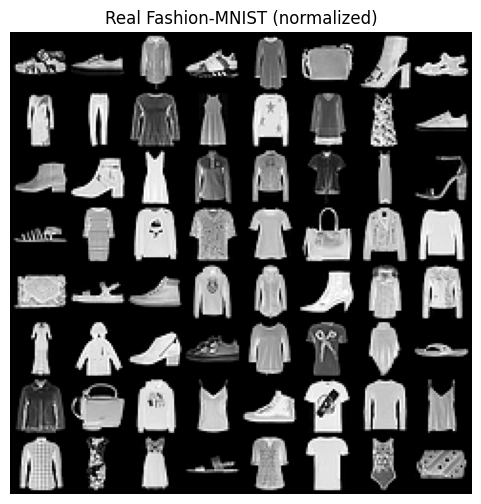

In [11]:
# Visual sanity check: show a small grid of REAL images.
real_batch, labels = next(iter(loader))
grid = make_grid(real_batch[:64], nrow=8, normalize=True)
plt.figure(figsize=(6,6))
plt.imshow(grid.permute(1,2,0))
plt.axis("off")
plt.title("Real Fashion-MNIST (normalized)")
plt.show()

### __(3) Define Generator__

In [12]:
class Generator(nn.Module):
    """
    Generator G:
      Input:  noise z of shape (B, Z_DIM)
      Output: fake image vector of shape (B, 784) in [-1, 1]
    """
    def __init__(self, z_dim=100, img_dim=784):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(z_dim, 256),
            nn.ReLU(True),

            nn.Linear(256, 512),
            nn.ReLU(True),

            nn.Linear(512, 1024),
            nn.ReLU(True),

            nn.Linear(1024, img_dim),
            nn.Tanh()                    # output matches normalized image range [-1,1]
        )

    def forward(self, z):
        return self.net(z)

__Learnable Layers in G:__ Noise (100) → 256 → 512 → 1024 → 784 (image pixels)

### __(4) Define Discriminator__

In [13]:
class Discriminator(nn.Module):
    """
    Discriminator D:
      Input:  image vector of shape (B, 784)
      Output: logit of shape (B, 1)

    NOTE: We output a LOGIT (not probability).
    We'll use BCEWithLogitsLoss which applies sigmoid internally.
    """
    def __init__(self, img_dim=784):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(img_dim, 512),
            nn.LeakyReLU(0.2, True),

            nn.Linear(512, 256),
            nn.LeakyReLU(0.2, True),

            nn.Linear(256, 1)  # logit
        )

    def forward(self, x):
        return self.net(x)

__Learnable Layers in D:__ 784 → 512 → 256 → 1

In [14]:
G = Generator(Z_DIM, IMG_DIM).to(device)
print(G)

Generator(
  (net): Sequential(
    (0): Linear(in_features=100, out_features=256, bias=True)
    (1): ReLU(inplace=True)
    (2): Linear(in_features=256, out_features=512, bias=True)
    (3): ReLU(inplace=True)
    (4): Linear(in_features=512, out_features=1024, bias=True)
    (5): ReLU(inplace=True)
    (6): Linear(in_features=1024, out_features=784, bias=True)
    (7): Tanh()
  )
)


In [15]:
D = Discriminator(IMG_DIM).to(device)
print(D)

Discriminator(
  (net): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): LeakyReLU(negative_slope=0.2, inplace=True)
    (2): Linear(in_features=512, out_features=256, bias=True)
    (3): LeakyReLU(negative_slope=0.2, inplace=True)
    (4): Linear(in_features=256, out_features=1, bias=True)
  )
)


### __(5) Loss and Optimizers__

In [16]:
# BCEWithLogitsLoss = sigmoid + binary cross entropy in one stable function.
criterion = nn.BCEWithLogitsLoss() # better than using nn.Sigmoid() and nn.BCELoss() separately as gradients can vanish

opt_G = optim.Adam(G.parameters(), lr=LR, betas=(0.5, 0.999))
opt_D = optim.Adam(D.parameters(), lr=LR, betas=(0.5, 0.999))

# fixed noise to visualize progress across epochs
fixed_z = torch.randn(64, Z_DIM, device=device)

G_losses, D_losses = [], []

### __(6) Training Loop__ (D step then G step)

In [17]:
for epoch in range(1, EPOCHS + 1):
    loader_pbar = tqdm(loader, desc=f'Epoch {epoch}/{EPOCHS}', leave=True)
    for real_imgs, _ in loader_pbar:
        # real_imgs: (B, 1, 28, 28) -> flatten to (B, 784)
        real_imgs = real_imgs.view(-1, IMG_DIM).to(device)
        B = real_imgs.size(0)

        # Create labels: real=1, fake=0
        real_labels = torch.ones(B, 1, device=device)    # answers we want the discriminator to learn: Real images → label 1
        fake_labels = torch.zeros(B, 1, device=device)   # Fake images → label 0. Note: D outputs logits, but the labels are still 0/1.

        # (A) Train Discriminator D
        # 1) Sample noise and generate fake images
        z = torch.randn(B, Z_DIM, device=device)         # fake images (shape (B, 784))
        fake_imgs = G(z).detach()                        # detach() prevents gradients flowing into G when we are updating D.

        # 2) D predictions on real and fake
        D_real = D(real_imgs)                            # D_real are logits for real images -- should be close to 1 (logit high)
        D_fake = D(fake_imgs)                            # D_fake are logits for fake images -- should be close to 0 (logit low)

        # 3) Compute discriminator loss
        loss_D_real = criterion(D_real, real_labels)     # D is trained on two tasks at once: Predict 1 for real and Predict 0 for fake
        loss_D_fake = criterion(D_fake, fake_labels)
        loss_D = (loss_D_real + loss_D_fake) * 0.5       # Average keeps scale balanced

        # 4) Update D only
        opt_D.zero_grad()
        loss_D.backward()
        opt_D.step()

        # (B) Train Generator G
        # 1) Sample new noise and generate fake images
        z = torch.randn(B, Z_DIM, device=device)         # generate new fake images
        fake_imgs = G(z)                                 # NO detach: We want gradients to update G

        # 2) Generator wants D(fake) -> 1 (fool D)
        D_fake_for_G = D(fake_imgs)
        loss_G = criterion(D_fake_for_G, real_labels)    # Even though images are fake, we use real_labels (1)

        # 3) Update G
        opt_G.zero_grad()
        loss_G.backward()
        opt_G.step()

        loader_pbar.set_postfix(D_loss=loss_D.item(), G_loss=loss_G.item())

    # log once per epoch
    G_losses.append(loss_G.item())
    D_losses.append(loss_D.item())

    # Save sample images each epoch for visual demo
    with torch.no_grad():
        samples = G(fixed_z).view(-1, 1, 28, 28)
        grid = make_grid(samples, nrow=8, normalize=True)
        save_image(grid, OUT_DIR / f"epoch_{epoch:03d}.png")



Epoch 1/20:   0%|          | 0/117 [00:00<?, ?it/s]

Epoch 2/20:   0%|          | 0/117 [00:00<?, ?it/s]

Epoch 3/20:   0%|          | 0/117 [00:00<?, ?it/s]

Epoch 4/20:   0%|          | 0/117 [00:00<?, ?it/s]

Epoch 5/20:   0%|          | 0/117 [00:00<?, ?it/s]

...

Epoch 16/20:   0%|          | 0/117 [00:00<?, ?it/s]

Epoch 17/20:   0%|          | 0/117 [00:00<?, ?it/s]

Epoch 18/20:   0%|          | 0/117 [00:00<?, ?it/s]

Epoch 19/20:   0%|          | 0/117 [00:00<?, ?it/s]

Epoch 20/20:   0%|          | 0/117 [00:00<?, ?it/s]

### __(8) Plot Loss Curves__

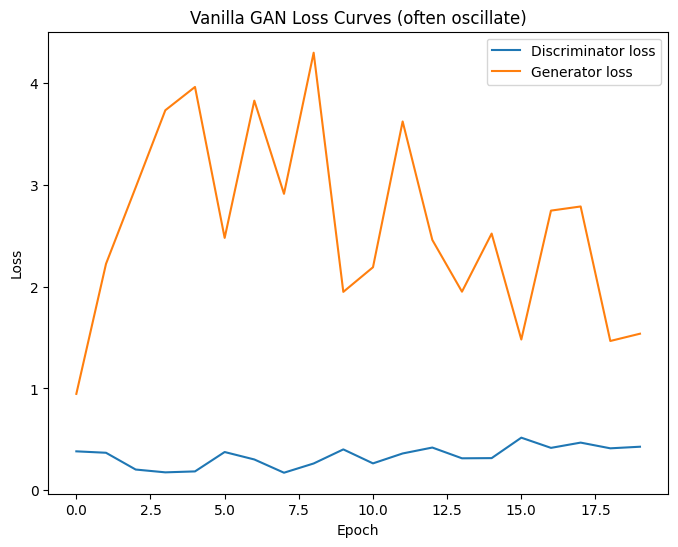

In [18]:
plt.figure(figsize=(8,6))
plt.plot(D_losses, label="Discriminator loss")
plt.plot(G_losses, label="Generator loss")
plt.legend()
plt.title("Vanilla GAN Loss Curves (often oscillate)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

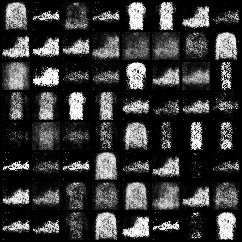

Saved samples in: gan_fashion_outputs


In [19]:
last_img = sorted(OUT_DIR.glob("epoch_*.png"))[-1]
display(Image.open(last_img))
print("Saved samples in:", OUT_DIR)